# 02 · Segmentation RFM et personas

**Question métier (Marketing)** : qui sont nos clients et comment les cibler ?

**Démarche** :

1. Calculer les scores RFM par personne (`customer_unique_id`) avec la requête SQL [`08_rfm_scores.sql`](../sql/queries/08_rfm_scores.sql) :
    - **R**écence : jours depuis le dernier achat ;
    - **F**réquence : nombre de commandes ;
    - **M**ontant : total payé.
2. Regrouper les clients avec K-means sur R, F et M, passés au logarithme puis standardisés.
3. Traduire les groupes en 3 personas, puis proposer 3 campagnes chiffrées.

Le code réutilisable est dans [`shoppulse/segmentation.py`](../src/shoppulse/segmentation.py).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from shoppulse.db import get_engine
from shoppulse.segmentation import (
    FEATURES,
    campaign_revenue,
    load_rfm,
    profile_segments,
    segment,
    silhouette_by_k,
)

plt.rcParams.update({"figure.figsize": (11, 3.5), "axes.grid": True, "grid.alpha": 0.3})
rfm = load_rfm(get_engine())
rfm[FEATURES] = rfm[FEATURES].astype(float)
rfm[FEATURES].describe().round(1)

,recency_days,frequency,monetary
count,94989.0,94989.0,94989.0
mean,288.3,1.0,165.7
std,153.0,0.2,226.7
min,45.0,1.0,9.6
25%,164.0,1.0,63.1
50%,269.0,1.0,107.9
75%,397.0,1.0,182.9
max,774.0,16.0,13664.1


Clients avec une seule commande : 97.0%


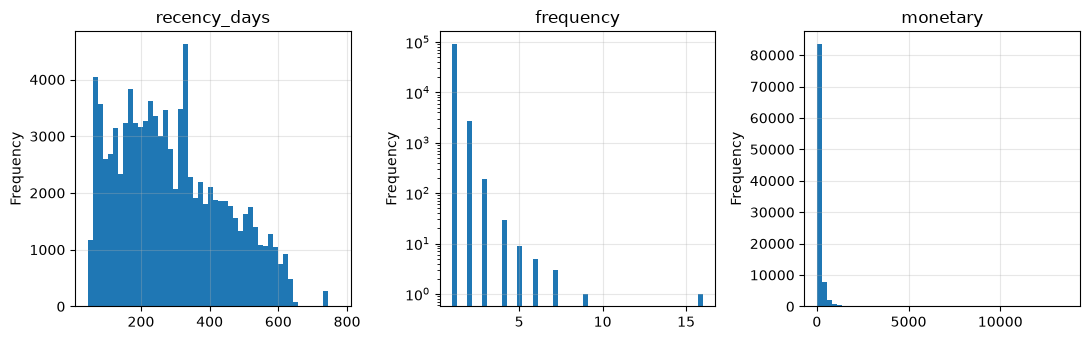

In [2]:
fig, axes = plt.subplots(1, 3)
for ax, feature in zip(axes, FEATURES, strict=True):
    rfm[feature].plot.hist(bins=50, ax=ax, logy=feature == "frequency", title=feature)
plt.tight_layout()
print(f"Clients avec une seule commande : {(rfm['frequency'] == 1).mean():.1%}")

**Lecture** : **97 % des clients n'ont passé qu'une seule commande**. La fréquence est donc presque constante, et ce sont la récence et le montant qui différencient les clients. C'est l'irritant décrit par la direction : le réachat stagne. Les trois variables sont asymétriques, d'où le passage au logarithme avant K-means. Sans lui, quelques gros paniers dicteraient les groupes.

## 1. Choix du nombre de segments

,silhouette
2,0.703
3,0.366
4,0.373
5,0.350
6,0.342


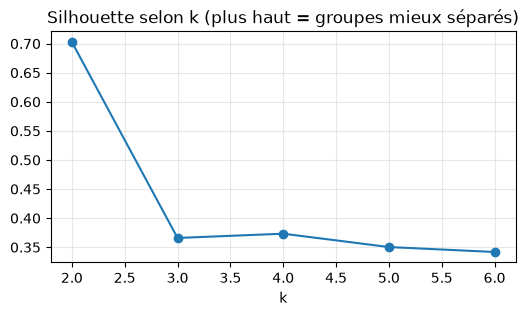

In [3]:
scores = pd.Series(silhouette_by_k(rfm, range(2, 7)), name="silhouette")
scores.plot(
    marker="o",
    title="Silhouette selon k (plus haut = groupes mieux séparés)",
    xlabel="k",
    figsize=(6, 3),
)
scores.round(3).to_frame()

**Choix : k = 3.**

- **k = 2** a la meilleure silhouette, mais il ne fait qu'isoler les clients ayant plus d'une commande, ce qui est trivial et ne sert pas au ciblage.
- **k = 3 et k = 4** sont presque à égalité (0,366 contre 0,373). k = 3 donne des groupes plus faciles à expliquer et colle à la demande du marketing : 3 personas, 3 campagnes.
- **Au-delà de 4**, la qualité baisse.

Une silhouette de 0,37 indique des groupes moyennement séparés. C'est normal pour une clientèle continue, et il faut voir les personas comme des tendances, pas des frontières nettes.

## 2. Les 3 personas

In [4]:
rfm["persona"] = segment(rfm)
summary = profile_segments(rfm, rfm["persona"])
summary["basket"] = (summary["monetary"] / summary["frequency"]).round(1)
summary

,customers,recency_days,frequency,monetary,revenue,customer_share_pct,revenue_share_pct,basket
persona,,,,,,,,
Fidèles,2888,271.4,2.1,308.4,890534.1,3.0,5.7,146.9
Récents,32973,131.8,1.0,175.5,5787158.1,34.7,36.8,175.5
Endormis,59128,376.5,1.0,153.3,9061444.8,62.2,57.6,153.3


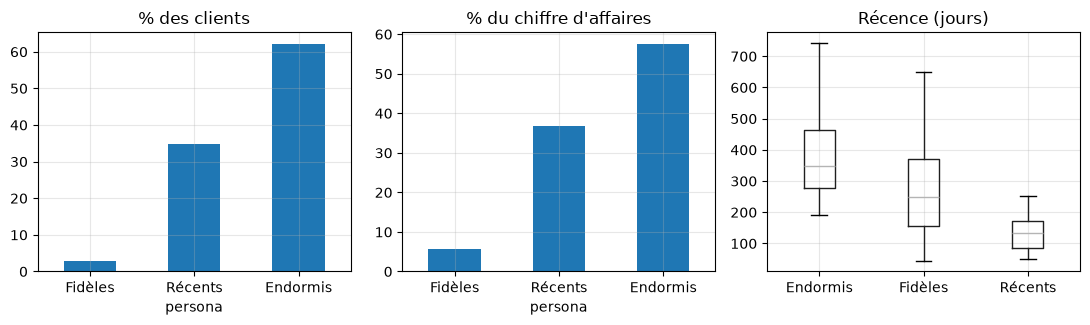

In [5]:
fig, axes = plt.subplots(1, 3)
summary["customer_share_pct"].plot.bar(ax=axes[0], rot=0, title="% des clients")
summary["revenue_share_pct"].plot.bar(
    ax=axes[1], rot=0, title="% du chiffre d'affaires"
)
rfm.boxplot(column="recency_days", by="persona", ax=axes[2], showfliers=False)
axes[2].set(title="Récence (jours)", xlabel="")
fig.suptitle("")
plt.tight_layout()

| Persona | Poids | Portrait | Enjeu |
|---|---|---|---|
| **Fidèles** | 3 % des clients, 6 % du CA | 2,1 commandes en moyenne, 308 R$ dépensés, dernier achat il y a environ 9 mois | Petit groupe qui revient déjà : il faut augmenter sa fréquence et le garder. |
| **Récents** | 35 % des clients, 37 % du CA | 1 commande il y a environ 4 mois, panier le plus élevé des acheteurs uniques (175 R$) | Ils sont encore « chauds » : c'est **la fenêtre pour déclencher un 2e achat**. |
| **Endormis** | 62 % des clients, 58 % du CA | 1 commande il y a plus d'un an, panier de 153 R$ | La plus grosse masse, mais elle est froide. La réactiver coûte plus cher : on vise un objectif modeste, à faible coût. |

Le constat clé est que **la base vit d'acheteurs uniques** : 97 % des clients et 94 % du CA. La croissance rentable passe par le réachat plutôt que par l'acquisition.

## 3. Trois campagnes chiffrées

CA additionnel = **clients ciblés × taux de conversion × panier moyen × (1 − remise)**.

Les taux de conversion sont des **hypothèses prudentes** : ce sont des ordres de grandeur courants de l'e-mailing e-commerce. Il faut les valider par un test A/B, avec un groupe témoin de 10 %, avant de généraliser.

In [6]:
campaigns = pd.DataFrame(
    [
        {
            "persona": "Récents",
            "campagne": "2e achat à J+30 : -10 % sur la catégorie déjà achetée",
            "conversion": 0.05,
            "remise": 0.10,
        },
        {
            "persona": "Endormis",
            "campagne": "Réactivation : -15 % valable 15 jours",
            "conversion": 0.02,
            "remise": 0.15,
        },
        {
            "persona": "Fidèles",
            "campagne": "Club fidélité : livraison offerte (≈ 20 R$/commande)",
            "conversion": 0.20,
            "remise": 0.0,
        },
    ]
).set_index("persona")
campaigns["clients"] = summary["customers"]
campaigns["panier"] = summary["basket"]
campaigns["commandes"] = (campaigns["clients"] * campaigns["conversion"]).round()
campaigns["ca_additionnel"] = [
    campaign_revenue(row.clients, row.conversion, row.panier, row.remise)
    for row in campaigns.itertuples()
]
# Coût de la livraison offerte aux Fidèles, déduit de leur CA.
campaigns.loc["Fidèles", "ca_additionnel"] -= campaigns.loc["Fidèles", "commandes"] * 20
campaigns["ca_additionnel"] = campaigns["ca_additionnel"].round(-3)
campaigns

,campagne,conversion,remise,clients,panier,commandes,ca_additionnel
persona,,,,,,,
Récents,2e achat à J+30 : -10 % sur la catégorie déjà ...,0.05,0.10,32973,175.5,1649.0,260000.0
Endormis,Réactivation : -15 % valable 15 jours,0.02,0.15,59128,153.3,1183.0,154000.0
Fidèles,Club fidélité : livraison offerte (≈ 20 R$/com...,0.20,0.00,2888,146.9,578.0,73000.0


In [7]:
repeat_before = (rfm["frequency"] > 1).mean()
new_repeaters = campaigns.loc[["Récents", "Endormis"], "commandes"].sum()
repeat_after = ((rfm["frequency"] > 1).sum() + new_repeaters) / len(rfm)
print(f"CA additionnel total : {campaigns['ca_additionnel'].sum():,.0f} R$")
print(f"Taux de réachat : {repeat_before:.1%} -> {repeat_after:.1%}")

CA additionnel total : 487,000 R$
Taux de réachat : 3.0% -> 6.0%


## Recommandations

| # | Cible | Action | Hypothèse | Gain estimé |
|---|---|---|---|---|
| 1 | Récents (33 000) | E-mail 30 jours après la livraison avec **-10 %** sur la catégorie déjà achetée | 5 % de conversion | **≈ 260 k R$**, soit environ 1 650 commandes |
| 2 | Endormis (59 000) | Campagne de réactivation **-15 % pendant 15 jours** | 2 % de conversion | **≈ 154 k R$**, soit environ 1 200 commandes |
| 3 | Fidèles (2 900) | **Club fidélité** avec livraison offerte | 20 % passent une commande de plus | **≈ 73 k R$** net du coût du port |

**Au total**, on gagne environ **490 k R$**, soit +3 % de CA sur la période. Le **taux de réachat passerait de 3 % à 6 %**.

**Ordre de priorité** : 1 → 3 → 2.

- La campagne Récents rapporte le plus et vise des clients encore réceptifs.
- La campagne Fidèles coûte peu et protège les meilleurs clients.
- La campagne Endormis touche le plus de monde mais convertit le moins.

**Précautions** : il faut valider chaque hypothèse de conversion par un test A/B avec un groupe témoin, et respecter le consentement e-mail des clients (RGPD, voir la note éthique). Enfin, l'EDA a montré qu'un retard fait chuter la note. Relancer un client qui vient d'être livré en retard serait donc contre-productif : on l'exclut de la campagne 1.